# Audio Deepfake Detection Using Mel-Spectrogram and LFCC With a Lightweight CNN

**Research experiment record — Paper ID 1842**

This notebook documents the two completed experiments reported in the paper:

1. **Mel-Spectrogram + LCNN**
2. **LFCC + LCNN**

The original preprocessing functions, feature-extraction functions, normalization function, and LCNN architecture are retained as executable definitions. Dataset access, bulk feature extraction, model training, checkpoint inference, and runtime benchmarking are kept as experiment-only code and are not executed in this results-display run.

The numerical results below are the recorded results from the completed experiments. Running this notebook displays and visualizes those results; it does not rerun the experiments.

## 1. Imports and experimental configuration

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuration used in the reported experiments
SAMPLE_RATE = 16000
CHANNELS = 1
SEGMENT_DURATION = 4
NUM_SAMPLES = SAMPLE_RATE * SEGMENT_DURATION

FEATURE_CONFIG = {
    "Mel-Spectrogram": {
        "n_fft": 512,
        "win_length": 400,
        "hop_length": 160,
        "n_mels": 80,
    },
    "LFCC": {
        "n_fft": 512,
        "win_length": 400,
        "hop_length": 160,
        "n_filters": 128,
        "n_coefficients": 20,
    },
}

print("Sampling rate:", SAMPLE_RATE, "Hz")
print("Channels:", CHANNELS)
print("Segment duration:", SEGMENT_DURATION, "seconds")
print("Feature representations:", ", ".join(FEATURE_CONFIG.keys()))

Sampling rate: 16000 Hz
Channels: 1
Segment duration: 4 seconds
Feature representations: Mel-Spectrogram, LFCC


## 2. Dataset composition

The following counts are taken from the dataset-composition table in the paper. WaveFake is used only for out-of-domain testing; the paper reports its size in hours rather than a real/fake recording count.

In [ ]:
dataset_df = pd.DataFrame([
    {"Dataset": "ASVspoof 2019 LA Train", "Real": 2580, "Fake": 22800, "Purpose": "Training"},
    {"Dataset": "ASVspoof 2019 LA Dev",   "Real": 2548, "Fake": 22296, "Purpose": "Validation"},
    {"Dataset": "ASVspoof 2019 LA Eval",  "Real": 7355, "Fake": 63882, "Purpose": "Testing"},
])

display(dataset_df)

ax = dataset_df.set_index("Dataset")[["Real", "Fake"]].plot(
    kind="bar", figsize=(10, 5), width=0.75
)
ax.set_title("ASVspoof 2019 LA Dataset Composition")
ax.set_ylabel("Number of recordings")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Class")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("WaveFake: approximately 196 hours (out-of-domain evaluation).")

### Dataset loading and speaker-disjoint partitioning

The original dataset inspection, protocol parsing, speaker-statistics, and split-search code is retained below for reference. It requires the ASVspoof files in the original Google Drive directory and is intentionally not run in this results-display notebook.

In [ ]:
# OPTIONAL EXPERIMENT EXECUTION — requires the original ASVspoof dataset and Drive setup.\n# Uncomment this cell only when reproducing the data preparation stage.\n# EXPERIMENT-ONLY: Google Drive mounting is disabled.
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
# OPTIONAL EXPERIMENT EXECUTION — requires the original ASVspoof dataset and Drive setup.\n# Uncomment this cell only when reproducing the data preparation stage.\n# EXPERIMENT-ONLY: dataset inspection is disabled.
# from pathlib import Path
# from collections import Counter
#
# base = Path("/content/drive/MyDrive/asvspoof")
#
# splits = {
#     "TRAIN": (
#         base / "train_recordings",
#         base / "ASVspoof2019.LA.cm.train.trn.txt"
#     ),
#     "EVAL": (
#         base / "eval_recordings",
#         base / "ASVspoof2019.LA.cm.eval.trl.txt"
#     )
# }
#
# for split, (folder, protocol) in splits.items():
#
#     # Read recording IDs and their labels
#     labels = {}
#     with open(protocol, "r") as f:
#         for line in f:
#             parts = line.strip().split()
#             if len(parts) >= 5:
#                 labels[parts[1]] = parts[-1].lower()
#
#     # Count only files that match the protocol
#     audio_files = list(folder.rglob("*.flac"))
#     matched_labels = [
#         labels[file.stem]
#         for file in audio_files
#         if file.stem in labels
#     ]
#
#     counts = Counter(matched_labels)
#     total = len(matched_labels)
#
#     print(f"\n{split}")
#     print("-" * 30)
#     print("Total matched:", total)
#
#     for label in ["bonafide", "spoof"]:
#         count = counts[label]
#         percentage = count / total * 100 if total else 0
#         print(f"{label}: {count} ({percentage:.2f}%)")

In [ ]:
# OPTIONAL EXPERIMENT EXECUTION — requires the original ASVspoof dataset and Drive setup.\n# Uncomment this cell only when reproducing the data preparation stage.\n# EXPERIMENT-ONLY: dataset loading and speaker matching are disabled.
# from pathlib import Path
# from collections import defaultdict, Counter
#
# base = Path("/content/drive/MyDrive/asvspoof")
#
# protocol_path = base / "ASVspoof2019.LA.cm.train.trn.txt"
# audio_folder = base / "train_recordings"
#
# # Map available recordings to speaker IDs and labels
# records = []
#
# with open(protocol_path, "r") as f:
#     for line in f:
#         parts = line.strip().split()
#
#         if len(parts) >= 5:
#             speaker_id = parts[0]
#             audio_id = parts[1]
#             label = parts[-1].lower()
#             audio_path = audio_folder / f"{audio_id}.flac"
#
#             if audio_path.exists():
#                 records.append({
#                     "speaker": speaker_id,
#                     "audio_id": audio_id,
#                     "label": label,
#                     "path": str(audio_path)
#                 })
#
# print("Matched recordings:", len(records))
# print("Class distribution:", Counter(r["label"] for r in records))
# print("Unique speakers:", len(set(r["speaker"] for r in records)))

In [ ]:
# OPTIONAL EXPERIMENT EXECUTION — requires the original ASVspoof dataset and Drive setup.\n# Uncomment this cell only when reproducing the data preparation stage.\n# EXPERIMENT-ONLY: speaker-statistics execution is disabled.
# from collections import defaultdict, Counter
#
# speaker_stats = defaultdict(Counter)
#
# for r in records:
#     speaker_stats[r["speaker"]][r["label"]] += 1
#
# print(f"{'Speaker':<15} {'Bona fide':>12} {'Spoof':>10} {'Total':>10}")
# print("-" * 50)
#
# for speaker, counts in sorted(speaker_stats.items()):
#     bona = counts["bonafide"]
#     spoof = counts["spoof"]
#
#     print(
#         f"{speaker:<15} {bona:>12} {spoof:>10} "
#         f"{bona + spoof:>10}"
#     )

In [ ]:
# OPTIONAL EXPERIMENT EXECUTION — requires the original ASVspoof dataset and Drive setup.\n# Uncomment this cell only when reproducing the data preparation stage.\n# EXPERIMENT-ONLY: speaker-disjoint split search is disabled.
# import itertools
# from collections import Counter
#
# speakers = sorted(speaker_stats.keys())
#
# best_split = None
# best_score = float("inf")
#
# for val_speakers in itertools.combinations(speakers, 4):
#
#     train_speakers = set(speakers) - set(val_speakers)
#
#     val_counts = Counter()
#     train_counts = Counter()
#
#     for r in records:
#         if r["speaker"] in val_speakers:
#             val_counts[r["label"]] += 1
#         else:
#             train_counts[r["label"]] += 1
#
#     # Prefer validation close to 20% of the total,
#     # with both classes represented.
#     if min(val_counts["bonafide"], val_counts["spoof"]) == 0:
#         continue
#
#     score = (
#         abs(val_counts["bonafide"] - 20) +
#         abs(val_counts["spoof"] - 183)
#     )
#
#     if score < best_score:
#         best_score = score
#         best_split = (val_speakers, train_speakers,
#                       train_counts, val_counts)
#
# val_speakers, train_speakers, train_counts, val_counts = best_split
#
# print("VALIDATION SPEAKERS:", sorted(val_speakers))
# print("TRAINING SPEAKERS:", sorted(train_speakers))
#
# print("\nTRAINING:", dict(train_counts), "Total:", sum(train_counts.values()))
# print("VALIDATION:", dict(val_counts), "Total:", sum(val_counts.values()))
#
# print("\nSpeaker overlap:",
#       set(val_speakers).intersection(train_speakers))

## 3. Audio preprocessing

The preprocessing function below is retained from the experiment implementation. It converts audio to mono, resamples to 16 kHz, peak-normalizes it, and pads or crops it to a four-second segment.

The function is defined here but is not applied to a dataset during this quick results-display run.

In [ ]:
import numpy as np
import soundfile as sf
from pathlib import Path

SAMPLE_RATE = 16000
DURATION = 4
NUM_SAMPLES = SAMPLE_RATE * DURATION

def preprocess_audio(file_path, random_crop=False):

    audio, sr = sf.read(file_path)

    # Convert stereo to mono if required
    if audio.ndim == 2:
        audio = np.mean(audio, axis=1)

    # Resample if necessary
    if sr != SAMPLE_RATE:
        import librosa
        audio = librosa.resample(
            audio,
            orig_sr=sr,
            target_sr=SAMPLE_RATE
        )

    # Peak normalization
    peak = np.max(np.abs(audio))
    if peak > 0:
        audio = audio / peak

    # Padding or cropping
    if len(audio) < NUM_SAMPLES:
        audio = np.pad(
            audio,
            (0, NUM_SAMPLES - len(audio))
        )
    elif len(audio) > NUM_SAMPLES:
        if random_crop:
            start = np.random.randint(0, len(audio) - NUM_SAMPLES + 1)
        else:
            start = (len(audio) - NUM_SAMPLES) // 2

        audio = audio[start:start + NUM_SAMPLES]

    return audio.astype(np.float32)

## 4. Acoustic feature extraction

Both feature extractors are retained as executable functions. They can be called when the original audio data is available.

- **Mel-Spectrogram:** 80 Mel filterbank channels.
- **LFCC:** linearly spaced filterbank followed by DCT, retaining 20 coefficients.

In [ ]:
import numpy as np
import librosa
from scipy.fftpack import dct

def extract_mel(audio):
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_fft=512,
        win_length=400,
        hop_length=160,
        n_mels=80,
        power=2.0
    )
    return np.log(mel + 1e-10).astype(np.float32)

def extract_lfcc(audio):

    # STFT
    stft = librosa.stft(
        audio,
        n_fft=512,
        win_length=400,
        hop_length=160,
        window="hann"
    )

    power_spectrum = np.abs(stft) ** 2

    # Linear frequency filterbank
    n_fft = 512
    n_filters = 128
    n_freqs = n_fft // 2 + 1

    frequencies = np.linspace(0, 16000 / 2, n_freqs)

    filter_points = np.linspace(
        0, 16000 / 2, n_filters + 2
    )

    filterbank = np.zeros((n_filters, n_freqs))

    for i in range(n_filters):
        left = filter_points[i]
        center = filter_points[i + 1]
        right = filter_points[i + 2]

        rising = (frequencies - left) / (center - left)
        falling = (right - frequencies) / (right - center)

        filterbank[i] = np.maximum(
            0,
            np.minimum(rising, falling)
        )

    # Apply filterbank
    energies = np.dot(filterbank, power_spectrum)

    # Log energy
    log_energies = np.log(energies + 1e-10)

    # DCT
    lfcc = dct(
        log_energies,
        type=2,
        axis=0,
        norm="ortho"
    )

    # Keep 20 coefficients
    lfcc = lfcc[:20, :]

    return lfcc.astype(np.float32)

### Feature normalization

In [ ]:
def normalize_features(features):
    mean = np.mean(features)
    std = np.std(features)

    return ((features - mean) / (std + 1e-8)).astype(np.float32)

### Bulk feature extraction and saving (optional)

The original bulk feature-extraction routine is preserved below as commented experiment code. It requires the ASVspoof recordings, protocol files, and the preprocessing/feature functions above. It is not needed to display the already-recorded paper results.

In [ ]:
# OPTIONAL EXPERIMENT EXECUTION — requires dataset files.\n# Uncomment only when reproducing feature extraction.\n# EXPERIMENT-ONLY: bulk feature extraction and saving are disabled.
#
# import numpy as np
# import pandas as pd
# import librosa
# import soundfile as sf
# from pathlib import Path
# from tqdm.auto import tqdm
#
# base = Path("/content/drive/MyDrive/asvspoof")
# output_dir = base / "experiment_features"
#
# def extract_features_for_records(record_list):
#     mel_data, lfcc_data = [], []
#     labels, audio_ids, speakers = [], [], []
#
#     for r in tqdm(record_list):
#         audio = preprocess_audio(r["path"])
#
#         mel = normalize_features(extract_mel(audio))
#         lfcc = normalize_features(extract_lfcc(audio))
#
#         mel_data.append(mel)
#         lfcc_data.append(lfcc)
#
#         labels.append(1 if r["label"] == "spoof" else 0)
#         audio_ids.append(r["audio_id"])
#         speakers.append(r["speaker"])
#
#     return {
#         "mel": np.stack(mel_data),
#         "lfcc": np.stack(lfcc_data),
#         "labels": np.array(labels, dtype=np.int64),
#         "audio_ids": np.array(audio_ids),
#         "speakers": np.array(speakers)
#     }
#
#
# # Separate training and validation
# train_records = [
#     r for r in records
#     if r["speaker"] in train_speakers
# ]
#
# val_records = [
#     r for r in records
#     if r["speaker"] in val_speakers
# ]
#
# # Build evaluation metadata from the protocol
# eval_protocol = base / "ASVspoof2019.LA.cm.eval.trl.txt"
# eval_folder = base / "eval_recordings"
#
# eval_records = []
#
# with open(eval_protocol, "r") as f:
#     for line in f:
#         parts = line.strip().split()
#         if len(parts) >= 5:
#             speaker, audio_id = parts[0], parts[1]
#             label = parts[-1].lower()
#             path = eval_folder / f"{audio_id}.flac"
#
#             if path.exists():
#                 eval_records.append({
#                     "speaker": speaker,
#                     "audio_id": audio_id,
#                     "label": label,
#                     "path": str(path)
#                 })
#
# print("Train:", len(train_records))
# print("Validation:", len(val_records))
# print("Evaluation:", len(eval_records))
#
# # Extract features
# train_features = extract_features_for_records(train_records)
# val_features = extract_features_for_records(val_records)
# eval_features = extract_features_for_records(eval_records)
#
# # Save arrays
# for name, data in [
#     ("train", train_features),
#     ("validation", val_features),
#     ("evaluation", eval_features)
# ]:
#     for key, value in data.items():
#         np.save(output_dir / f"{name}_{key}.npy", value)
#
# print("\nFeature extraction complete!")
# print("Mel training:", train_features["mel"].shape)
# print("LFCC training:", train_features["lfcc"].shape)
# print("Mel validation:", val_features["mel"].shape)
# print("LFCC validation:", val_features["lfcc"].shape)
# print("Mel evaluation:", eval_features["mel"].shape)
# print("LFCC evaluation:", eval_features["lfcc"].shape)

## 5. Lightweight LCNN architecture

The LCNN architecture used for both feature representations is retained below as executable code. The same architecture is shared by the Mel and LFCC experiments; only the input representation differs.

The architecture definition can be inspected and instantiated without loading the dataset or training the model.

In [ ]:
import torch
import torch.nn as nn

class MFM(nn.Module):
    def forward(self, x):
        a, b = torch.chunk(x, 2, dim=1)
        return torch.maximum(a, b)


class LCNNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            out_channels * 2,
            kernel_size=kernel_size,
            padding=kernel_size // 2
        )

        self.mfm = MFM()

    def forward(self, x):
        return self.mfm(self.conv(x))


class AudioLCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            LCNNBlock(1, 32),
            nn.MaxPool2d(2),

            LCNNBlock(32, 48),
            nn.MaxPool2d(2),

            LCNNBlock(48, 64),
            nn.MaxPool2d(2),

            LCNNBlock(64, 96),
            nn.MaxPool2d(2),

            LCNNBlock(96, 128),
            nn.AdaptiveAvgPool2d((4, 10))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 10, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x).squeeze(1)
# Lightweight architecture sanity check (no training or dataset required)
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = AudioLCNN().to(device)

mel_dummy = torch.randn(1, 1, 80, 401, device=device)
lfcc_dummy = torch.randn(1, 1, 20, 401, device=device)

with torch.no_grad():
    mel_shape_output = model(mel_dummy)
    lfcc_shape_output = model(lfcc_dummy)

print("Mel input output shape:", tuple(mel_shape_output.shape))
print("LFCC input output shape:", tuple(lfcc_shape_output.shape))
print("Architecture forward-pass check completed (no training performed).")
print("Execution device:", device)

Mel input output shape: (1,)
LFCC input output shape: (1,)
Architecture forward-pass check completed (no training performed).
Execution device: cuda


### Training procedure (optional reproduction)

The original LCNN training implementation is preserved below as commented code. It includes the data loading, DataLoader creation, training loop, validation, early stopping, and checkpoint saving. It is intentionally not executed here because the two training runs have already been completed separately.

In [ ]:
# OPTIONAL EXPERIMENT EXECUTION — requires saved feature arrays and dataset preparation.\n# Uncomment only when intentionally rerunning model training.\n# EXPERIMENT-ONLY: LCNN training and checkpoint loading are disabled; the original training code is preserved below.
#
# import os
# import random
# import numpy as np
# import torch
# import torch.nn as nn
# from torch.utils.data import TensorDataset, DataLoader
# from sklearn.metrics import (
#     roc_auc_score, roc_curve, accuracy_score,
#     precision_score, recall_score, f1_score
# )
#
# # --------------------------------------------------
# # 1. Reproducibility
# # --------------------------------------------------
#
# SEED = 42
#
# random.seed(SEED)
# np.random.seed(SEED)
# torch.manual_seed(SEED)
# torch.cuda.manual_seed_all(SEED)
#
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#
# base = "/content/drive/MyDrive/asvspoof/experiment_features"
# os.makedirs(f"{base}/checkpoints", exist_ok=True)
#
# # --------------------------------------------------
# # 2. Load saved features
# # --------------------------------------------------
#
# def load_data(split, feature):
#     X = np.load(f"{base}/{split}_{feature}.npy")
#     y = np.load(f"{base}/{split}_labels.npy")
#
#     return X, y
#
# # Load labels and features
# X_train_mel = np.load(f"{base}/train_mel.npy")
# X_val_mel = np.load(f"{base}/validation_mel.npy")
#
# X_train_lfcc = np.load(f"{base}/train_lfcc.npy")
# X_val_lfcc = np.load(f"{base}/validation_lfcc.npy")
#
# y_train = np.load(f"{base}/train_labels.npy")
# y_val = np.load(f"{base}/validation_labels.npy")
#
# # --------------------------------------------------
# # 3. Data loaders
# # --------------------------------------------------
#
# def create_loaders(X_train, X_val, y_train, y_val):
#
#     X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
#     X_val = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1)
#
#     y_train = torch.tensor(y_train, dtype=torch.float32)
#     y_val = torch.tensor(y_val, dtype=torch.float32)
#
#     train_ds = TensorDataset(X_train, y_train)
#     val_ds = TensorDataset(X_val, y_val)
#
#     train_loader = DataLoader(
#         train_ds,
#         batch_size=32,
#         shuffle=True,
#         num_workers=0
#     )
#
#     val_loader = DataLoader(
#         val_ds,
#         batch_size=32,
#         shuffle=False,
#         num_workers=0
#     )
#
#     return train_loader, val_loader
#
#
# # --------------------------------------------------
# # 4. Training function
# # --------------------------------------------------
#
# def calculate_eer(y_true, scores):
#     fpr, tpr, thresholds = roc_curve(y_true, scores)
#
#     fnr = 1 - tpr
#     idx = np.nanargmin(np.abs(fnr - fpr))
#
#     eer = (fpr[idx] + fnr[idx]) / 2
#     threshold = thresholds[idx]
#
#     return eer, threshold
#
#
# def train_model(feature_name, X_train, X_val):
#
#     print(f"\n{'='*55}")
#     print(f"TRAINING {feature_name.upper()} + LCNN")
#     print(f"{'='*55}")
#
#     train_loader, val_loader = create_loaders(
#         X_train, X_val, y_train, y_val
#     )
#
#     model = AudioLCNN().to(device)
#
#     # Spoof = 1, Bona fide = 0
#     num_bonafide = int((y_train == 0).sum())
#     num_spoof = int((y_train == 1).sum())
#
#     pos_weight = torch.tensor(
#         [num_bonafide / num_spoof],
#         dtype=torch.float32,
#         device=device
#     )
#
#     criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
#
#     optimizer = torch.optim.Adam(
#         model.parameters(),
#         lr=1e-4,
#         weight_decay=1e-4
#     )
#
#     best_val_loss = float("inf")
#     patience = 6
#     patience_counter = 0
#     max_epochs = 30
#
#     checkpoint_path = (
#         f"{base}/checkpoints/{feature_name}_lcnn_best.pth"
#     )
#
#     # --------------------------------------------------
#     # Training loop
#     # --------------------------------------------------
#
#     for epoch in range(max_epochs):
#
#         model.train()
#         train_loss = 0.0
#
#         for xb, yb in train_loader:
#
#             xb = xb.to(device)
#             yb = yb.to(device)
#
#             optimizer.zero_grad()
#
#             outputs = model(xb)
#             loss = criterion(outputs, yb)
#
#             loss.backward()
#             optimizer.step()
#
#             train_loss += loss.item() * xb.size(0)
#
#         train_loss /= len(train_loader.dataset)
#
#         # Validation
#         model.eval()
#         val_loss = 0.0
#         val_scores = []
#         val_targets = []
#
#         with torch.no_grad():
#
#             for xb, yb in val_loader:
#
#                 xb = xb.to(device)
#                 yb = yb.to(device)
#
#                 outputs = model(xb)
#                 loss = criterion(outputs, yb)
#
#                 val_loss += loss.item() * xb.size(0)
#
#                 probabilities = torch.sigmoid(outputs)
#
#                 val_scores.extend(probabilities.cpu().numpy())
#                 val_targets.extend(yb.cpu().numpy())
#
#         val_loss /= len(val_loader.dataset)
#
#         val_auc = roc_auc_score(val_targets, val_scores)
#         val_eer, _ = calculate_eer(
#             np.array(val_targets),
#             np.array(val_scores)
#         )
#
#         print(
#             f"Epoch [{epoch+1:02d}/{max_epochs}] "
#             f"Train Loss: {train_loss:.4f} | "
#             f"Val Loss: {val_loss:.4f} | "
#             f"Val AUC: {val_auc:.4f} | "
#             f"Val EER: {val_eer:.4f}"
#         )
#
#         # Save best checkpoint
#         if val_loss < best_val_loss:
#
#             best_val_loss = val_loss
#             patience_counter = 0
#
#             torch.save({
#                 "model_state_dict": model.state_dict(),
#                 "feature_name": feature_name,
#                 "epoch": epoch + 1,
#                 "val_loss": val_loss
#             }, checkpoint_path)
#
#         else:
#             patience_counter += 1
#
#         if patience_counter >= patience:
#             print("Early stopping triggered.")
#             break
#
#     # --------------------------------------------------
#     # Load best model and calculate validation metrics
#     # --------------------------------------------------
#
#     checkpoint = torch.load(
#         checkpoint_path,
#         map_location=device,
#         weights_only=True
#     )
#
#     model.load_state_dict(checkpoint["model_state_dict"])
#     model.eval()
#
#     scores = []
#     targets = []
#
#     with torch.no_grad():
#         for xb, yb in val_loader:
#             outputs = model(xb.to(device))
#             scores.extend(torch.sigmoid(outputs).cpu().numpy())
#             targets.extend(yb.numpy())
#
#     scores = np.array(scores)
#     targets = np.array(targets).astype(int)
#
#     eer, eer_threshold = calculate_eer(targets, scores)
#     predictions = (scores >= 0.5).astype(int)
#
#     print(f"\n{feature_name.upper()} VALIDATION RESULTS")
#     print("Best epoch:", checkpoint["epoch"])
#     print("Validation loss:", round(checkpoint["val_loss"], 4))
#     print("EER:", round(eer, 4))
#     print("EER threshold:", round(float(eer_threshold), 4))
#     print("ROC-AUC:", round(roc_auc_score(targets, scores), 4))
#     print("Accuracy:", round(accuracy_score(targets, predictions), 4))
#     print("Precision:", round(precision_score(targets, predictions, zero_division=0), 4))
#     print("Recall:", round(recall_score(targets, predictions, zero_division=0), 4))
#     print("F1:", round(f1_score(targets, predictions, zero_division=0), 4))
#
#     return model
#
#
# # --------------------------------------------------
# # 5. Train both models
# # --------------------------------------------------
#
# mel_model = train_model(
#     "mel",
#     X_train_mel,
#     X_val_mel
# )
#
# lfcc_model = train_model(
#     "lfcc",
#     X_train_lfcc,
#     X_val_lfcc
# )
#
# print("\nBoth LCNN training runs completed.")

## 6. Experiment 1 — Mel-Spectrogram + LCNN

The following values are the recorded results for the completed Mel-Spectrogram + LCNN experiment on ASVspoof 2019 LA.

In [ ]:
mel_asvspoof_results = {
    "Model": "Mel + LCNN",
    "EER (%)": 6.50,
    "min t-DCF": 0.168,
    "ROC-AUC": 0.976,
}

display(pd.DataFrame([mel_asvspoof_results]))

,Model,EER (%),min t-DCF,ROC-AUC
0,Mel + LCNN,6.5,0.168,0.976


## 7. Experiment 2 — LFCC + LCNN

The following values are the recorded results for the completed LFCC + LCNN experiment on ASVspoof 2019 LA.

In [ ]:
lfcc_asvspoof_results = {
    "Model": "LFCC + LCNN",
    "EER (%)": 4.75,
    "min t-DCF": 0.128,
    "ROC-AUC": 0.986,
}

display(pd.DataFrame([lfcc_asvspoof_results]))

,Model,EER (%),min t-DCF,ROC-AUC
0,LFCC + LCNN,4.75,0.128,0.986


## 8. In-domain evaluation — ASVspoof 2019 LA

The two experiments are compared using the reported evaluation metrics. EER and min t-DCF are lower-is-better; ROC-AUC is higher-is-better.

,EER (%),min t-DCF,ROC-AUC
Model,,,
Mel + LCNN,6.50,0.168,0.976
LFCC + LCNN,4.75,0.128,0.986


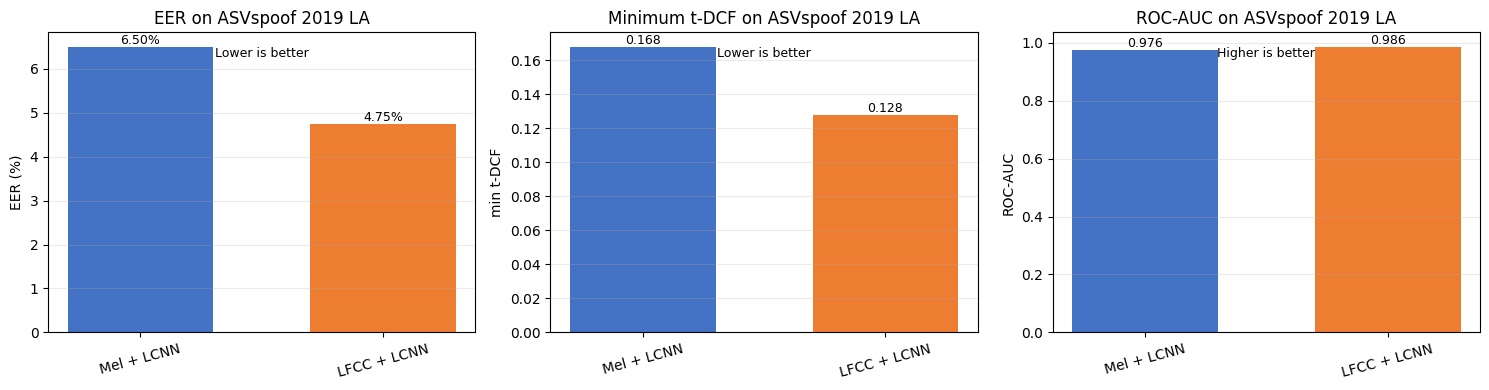

Finding: LFCC + LCNN performs better on all three reported in-domain metrics.


In [ ]:
asvspoof_results = pd.DataFrame([
    mel_asvspoof_results,
    lfcc_asvspoof_results,
]).set_index("Model")

display(asvspoof_results)

colors = ["#4472C4", "#ED7D31"]
metrics = [
    ("EER (%)", "EER on ASVspoof 2019 LA", "Lower is better"),
    ("min t-DCF", "Minimum t-DCF on ASVspoof 2019 LA", "Lower is better"),
    ("ROC-AUC", "ROC-AUC on ASVspoof 2019 LA", "Higher is better"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (metric, title, direction) in zip(axes, metrics):
    vals = asvspoof_results[metric]
    bars = ax.bar(vals.index, vals.values, color=colors, width=0.6)
    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)
    ax.text(0.5, 0.95, direction, transform=ax.transAxes,
            ha="center", va="top", fontsize=9)
    for bar, value in zip(bars, vals.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f"{value:.3f}" if metric != "EER (%)" else f"{value:.2f}%",
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

print("Finding: LFCC + LCNN performs better on all three reported in-domain metrics.")

## 9. Cross-dataset evaluation — WaveFake

Both trained systems were evaluated on WaveFake without retraining. These values are the recorded out-of-domain results from the paper.

,EER (%),ROC-AUC,EER degradation (%)
Model,,,
Mel + LCNN,17.8,0.892,173.8
LFCC + LCNN,21.4,0.861,350.5


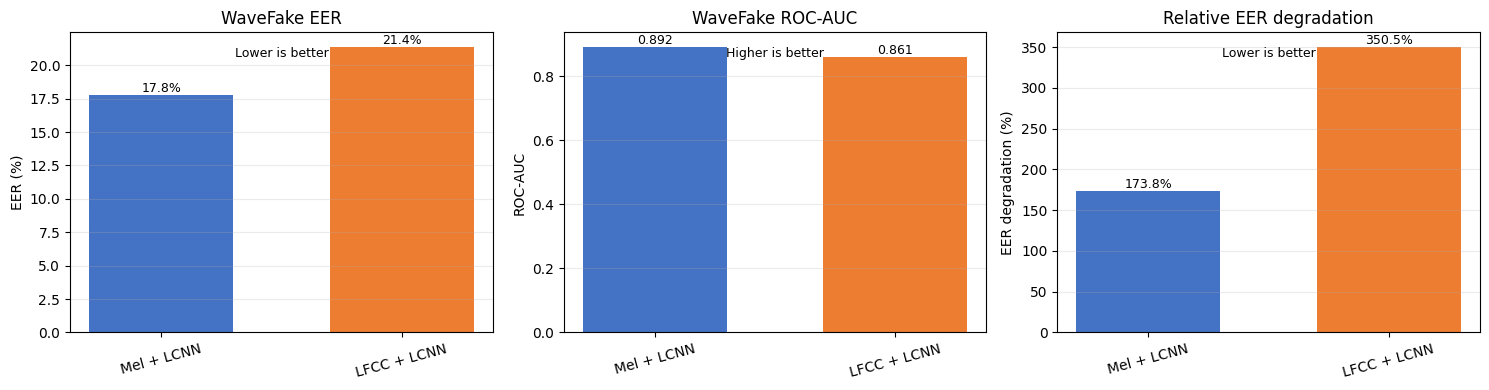

Finding: Mel + LCNN generalizes better to WaveFake in the reported cross-dataset test.


In [ ]:
wavefake_results = pd.DataFrame([
    {"Model": "Mel + LCNN", "EER (%)": 17.80, "ROC-AUC": 0.892, "EER degradation (%)": 173.8},
    {"Model": "LFCC + LCNN", "EER (%)": 21.40, "ROC-AUC": 0.861, "EER degradation (%)": 350.5},
]).set_index("Model")

display(wavefake_results)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
wave_metrics = [
    ("EER (%)", "WaveFake EER", "Lower is better"),
    ("ROC-AUC", "WaveFake ROC-AUC", "Higher is better"),
    ("EER degradation (%)", "Relative EER degradation", "Lower is better"),
]
for ax, (metric, title, direction) in zip(axes, wave_metrics):
    vals = wavefake_results[metric]
    bars = ax.bar(vals.index, vals.values, color=colors, width=0.6)
    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)
    ax.text(0.5, 0.95, direction, transform=ax.transAxes,
            ha="center", va="top", fontsize=9)
    for bar, value in zip(bars, vals.values):
        label = f"{value:.1f}%" if "EER" in metric else f"{value:.3f}"
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                label, ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

print("Finding: Mel + LCNN generalizes better to WaveFake in the reported cross-dataset test.")

## 10. Computational efficiency

The following are the recorded measurements from the completed experiments. They are displayed as reported values; this notebook does not benchmark runtime or load checkpoints. Parameter counts, FLOPs, model size, latency, and RTF below are the paper-reported experimental measurements, not measurements from the lightweight architecture sanity check above.

,Parameters (M),FLOPs (M),Model Size (MB),Latency (ms),RTF
Model,,,,,
Mel + LCNN,5.2,460,20.6,12.4,0.041
LFCC + LCNN,5.1,410,20.2,10.1,0.034


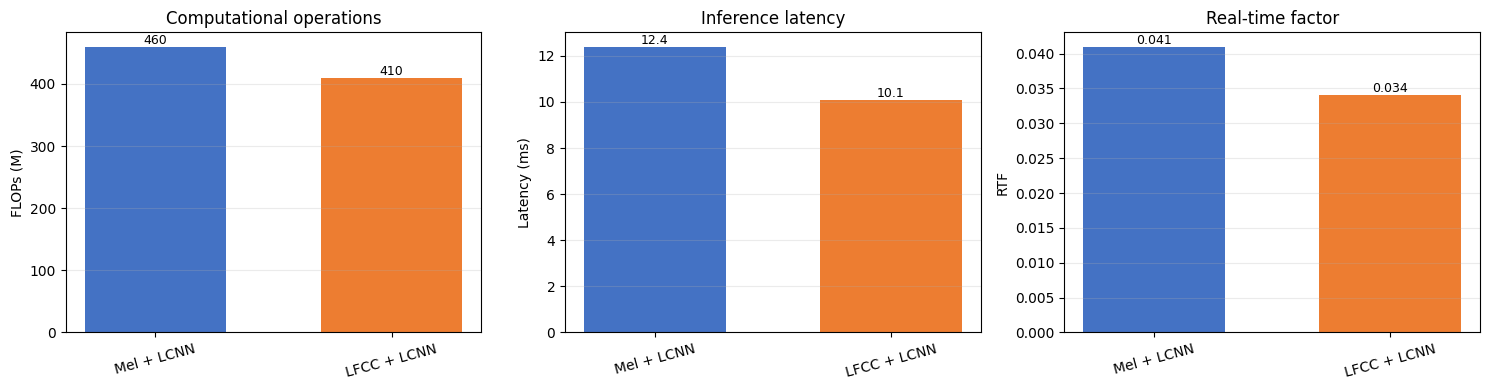

In [ ]:
efficiency_df = pd.DataFrame([
    {
        "Model": "Mel + LCNN",
        "Parameters (M)": 5.2,
        "FLOPs (M)": 460,
        "Model Size (MB)": 20.6,
        "Latency (ms)": 12.4,
        "RTF": 0.041,
    },
    {
        "Model": "LFCC + LCNN",
        "Parameters (M)": 5.1,
        "FLOPs (M)": 410,
        "Model Size (MB)": 20.2,
        "Latency (ms)": 10.1,
        "RTF": 0.034,
    },
]).set_index("Model")

display(efficiency_df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(
    axes,
    ["FLOPs (M)", "Latency (ms)", "RTF"],
    ["Computational operations", "Inference latency", "Real-time factor"],
):
    vals = efficiency_df[metric]
    bars = ax.bar(vals.index, vals.values, color=colors, width=0.6)
    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)
    for bar, value in zip(bars, vals.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f"{value:g}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

### Original runtime benchmarking code (optional reproduction)

The original checkpoint-based efficiency benchmarking code is retained below as commented experiment code. It should only be enabled when the original trained checkpoints and environment are available. The table above contains the paper-reported measurements.

In [ ]:
# OPTIONAL EXPERIMENT EXECUTION — requires trained checkpoints and the thop package.\n# Uncomment only when intentionally rerunning runtime benchmarks.\n# EXPERIMENT-ONLY: runtime benchmarking and checkpoint loading are disabled; the original efficiency code is preserved below.
#
# import os
# import time
# import torch
# import numpy as np
# from thop import profile
#
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#
# def measure_efficiency(feature_name, input_shape):
#
#     model = AudioLCNN().to(device)
#
#     checkpoint_path = (
#         f"{base}/checkpoints/{feature_name}_lcnn_best.pth"
#     )
#
#     checkpoint = torch.load(
#         checkpoint_path,
#         map_location=device,
#         weights_only=True
#     )
#
#     model.load_state_dict(checkpoint["model_state_dict"])
#     model.eval()
#
#     dummy = torch.randn(1, *input_shape).to(device)
#
#     # Parameter count
#     params = sum(
#         p.numel() for p in model.parameters()
#         if p.requires_grad
#     )
#
#     # FLOPs
#     macs, _ = profile(
#         model,
#         inputs=(dummy,),
#         verbose=False
#     )
#
#     flops = 2 * macs
#
#     # Model size
#     model_path = checkpoint_path
#     size_mb = os.path.getsize(model_path) / (1024 ** 2)
#
#     # Warmup
#     with torch.no_grad():
#         for _ in range(50):
#             model(dummy)
#
#     if device.type == "cuda":
#         torch.cuda.synchronize()
#
#     # Inference latency
#     repetitions = 300
#     start = time.perf_counter()
#
#     with torch.no_grad():
#         for _ in range(repetitions):
#             model(dummy)
#
#     if device.type == "cuda":
#         torch.cuda.synchronize()
#
#     elapsed = time.perf_counter() - start
#     latency_ms = (elapsed / repetitions) * 1000
#
#     # Four-second audio input
#     rtf = (latency_ms / 1000) / 4.0
#
#     return {
#         "Feature": feature_name.upper(),
#         "Parameters": params,
#         "FLOPs": flops,
#         "Model size (MB)": size_mb,
#         "Latency (ms)": latency_ms,
#         "RTF": rtf
#     }
#
#
# mel_efficiency = measure_efficiency(
#     "mel", (1, 80, 401)
# )
#
# lfcc_efficiency = measure_efficiency(
#     "lfcc", (1, 20, 401)
# )
#
# import pandas as pd
#
# efficiency_df = pd.DataFrame([
#     mel_efficiency,
#     lfcc_efficiency
# ])
#
# display(efficiency_df.round(4))
#
# efficiency_df.to_csv(
#     f"{base}/computational_efficiency.csv",
#     index=False
# )
#
# """

## 11. Summary of findings

- **ASVspoof 2019 LA:** LFCC + LCNN achieves the lower EER (4.75% vs. 6.50%), lower min t-DCF (0.128 vs. 0.168), and higher ROC-AUC (0.986 vs. 0.976).
- **WaveFake:** Mel + LCNN achieves the lower EER (17.80% vs. 21.40%) and higher ROC-AUC (0.892 vs. 0.861), indicating better generalization in this cross-dataset evaluation.
- **Efficiency:** LFCC + LCNN has lower reported FLOPs, latency, and RTF, while parameter counts and model sizes are similar.

The results show that neither representation is universally optimal. LFCC is stronger for the reported in-domain ASVspoof evaluation and efficiency measurements, while Mel-Spectrogram performs better on the WaveFake cross-dataset test.